# London collision spatial validation

Validate London collision membership to support the fixed Croydon study frame in the [research framework](../README.md#research-framework). Saved outputs contain no errors; the export message reports retained artifacts with matching input hashes, and both figures are saved with the membership-example PNG checked visually. See the [saved execution evidence](../docs/methods-and-validation.md#saved-execution-and-figure-evidence) for metadata details and the limits of fresh-kernel verification.

## Task 3: Spatial validation

### 3.1 Inputs, parameters and provenance

**Purpose:** run from `notebooks/` with notebook 01's candidate CSV and the documented inputs. Verify boundary and guide checksums against the manifest and record input hashes and package versions for reproducibility.


In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import NamedTemporaryFile
import hashlib
import json
import os
from importlib.metadata import version
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from pyproj import CRS, network
from pyproj.transformer import TransformerGroup

DATA_DIR = Path(os.environ.get("COMP1890_DATA_DIR", "../data")).expanduser()
BOUNDARY_PATH = Path(os.environ.get(
    "COMP1890_BOUNDARY_PATH", str(DATA_DIR / "ons-lad-december-2024-uk-bfe.gpkg")
)).expanduser()
CANDIDATE_PATH = DATA_DIR / "derived/pedestrian_collision_candidates.csv"
GUIDE_PATH = DATA_DIR / "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx"
OUTPUT_DIR = DATA_DIR / "derived" / "spatial_validation_closure"

BOUNDARY_LAYER = "LAD_DEC_24_UK_BFE"
CODE, NAME = "LAD24CD", "LAD24NM"
GRID_CRS = "EPSG:27700"
# Keep unset until documentary evidence and a tolerance rationale are available.
GEOGRAPHIC_CRS = None
GEOGRAPHIC_CRS_EVIDENCE = ""
COORDINATE_TOLERANCE_M = None
TOLERANCE_RATIONALE = ""
# Export the existing membership-example figure only; raw and validation files stay protected.
EXPORT_FIGURES = True
FIGURE_DIR = Path(os.environ.get("COMP1890_FIGURE_DIR", "../evidence")).expanduser()


def save_report_figure(figure, filename):
    """Skip identical PNGs and replace changed images only after a complete save."""
    if not EXPORT_FIGURES:
        return
    output_path = FIGURE_DIR / filename
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
        png_bytes = buffer.getvalue()
    existed = output_path.exists()
    if existed and output_path.read_bytes() == png_bytes:
        print(f"Figure unchanged; kept existing PNG: {output_path}")
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    temporary_path = None
    try:
        # A closed temporary file in the same directory supports atomic replacement.
        with NamedTemporaryFile(mode="wb", dir=FIGURE_DIR,
                                prefix=f".{output_path.name}.", suffix=".tmp",
                                delete=False) as handle:
            temporary_path = Path(handle.name)
            handle.write(png_bytes)
        os.replace(temporary_path, output_path)
    finally:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
    action = "Updated" if existed else "Saved"
    print(f"{action} figure: {output_path}")

network.set_network_enabled(False)
versions = {name: version(name) for name in (
    "pandas", "geopandas", "shapely", "pyproj", "pyogrio", "matplotlib"
)}
display(pd.Series(versions, name="installed_version"))
manifest_path = DATA_DIR / "download-manifest.json"
for path in [BOUNDARY_PATH, CANDIDATE_PATH, GUIDE_PATH, manifest_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Required input missing: {path}. Check the documented input parameters.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
entries = {entry["file"]: entry for entry in manifest["files"]}
input_hashes = {}
for label, path in {"boundary": BOUNDARY_PATH, "guide": GUIDE_PATH, "candidates": CANDIDATE_PATH}.items():
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    input_hashes[label] = digest
    if label != "candidates":
        entry = entries.get(path.name)
        if entry is None or path.stat().st_size != entry["bytes"] or digest != entry["sha256"]:
            raise ValueError(f"Input differs from its manifest entry: {path.name}")
display(pd.Series(input_hashes, name="sha256"))

pandas         3.1.1
geopandas      1.2.0
shapely        2.2.0
pyproj         3.8.0
pyogrio       0.13.0
matplotlib    3.11.2
Name: installed_version, dtype: str

boundary      a421a026170391ade115e7424b8c4e06e682e0290978b8...
guide         51b08606ef3dad1ae5d4c8726241b022fc8e4bbdc910ef...
candidates    6599e3a378f930db908b225c5b554c624ee94159a5f419...
Name: sha256, dtype: str

**Findings:** boundary and guide verification passed, and the candidate checksum and spatial package versions were recorded. These identify the run's inputs and environment, not geographic accuracy.


### 3.2 Boundary geometry and district reconciliation

**Purpose:** check the 33 London districts' CRS, codes, names, geometry validity and overlaps against the guide. Use [full-resolution boundaries](../docs/references.md#r04) without repairing or simplifying the source polygons.


In [2]:
london = gpd.read_file(
    BOUNDARY_PATH, layer=BOUNDARY_LAYER, where=f"{CODE} LIKE 'E09%'", engine="pyogrio"
)
if london.crs is None:
    raise ValueError("Boundary CRS is missing; do not infer it from coordinate values.")
source_boundary_crs = london.crs.to_string()
if not {CODE, NAME}.issubset(london.columns):
    raise ValueError("The selected layer lacks the documented district fields.")
london = london[[CODE, NAME, "geometry"]].sort_values(CODE).reset_index(drop=True)
if len(london) != 33 or london[CODE].isna().any() or not london[CODE].is_unique:
    raise ValueError("Expected 33 unique London district codes, including City of London.")
if (london.geometry.isna().any() or london.geometry.is_empty.any()
        or not london.geom_type.isin(["Polygon", "MultiPolygon"]).all()
        or not london.geometry.is_valid.all()):
    raise ValueError("Missing, empty, invalid or non-polygon boundaries require investigation; no automatic repair applied.")
london = london.to_crs(GRID_CRS)
guide = pd.read_excel(GUIDE_PATH, sheet_name="2024_code_list", dtype=str,
                     keep_default_na=False, engine="openpyxl")
guide_london = guide.loc[
    guide["table"].eq("collision") & guide["field name"].eq("local_authority_ons_district")
    & guide["code/format"].str.fullmatch(r"E090000[0-9]{2}"),
    ["code/format", "label"],
].drop_duplicates()
if guide_london["code/format"].duplicated().any() or set(guide_london["code/format"]) != set(london[CODE]):
    raise ValueError("Boundary codes do not reconcile uniquely with the supplied guide.")
name_check = london[[CODE, NAME]].merge(guide_london, left_on=CODE, right_on="code/format")
name_check["name_agrees"] = name_check[NAME].str.casefold().eq(name_check["label"].str.casefold())
overlap_rows = []
pairs = gpd.sjoin(london[["geometry"]], london[["geometry"]], predicate="intersects", how="inner")
for left, right in zip(pairs.index, pairs["index_right"], strict=True):
    if left < right:
        area = london.geometry.iloc[left].intersection(london.geometry.iloc[right]).area
        if area > 0:
            overlap_rows.append({"code_a": london[CODE].iloc[left], "code_b": london[CODE].iloc[right],
                                 "overlap_m2": float(area)})
boundary_overlaps = pd.DataFrame(overlap_rows, columns=["code_a", "code_b", "overlap_m2"])
print("Source CRS:", source_boundary_crs, "Analysis CRS:", london.crs)
display(name_check[[CODE, NAME, "label", "name_agrees"]])
print("Positive-area boundary intersections; investigate their extent rather than auto-repairing:")
display(boundary_overlaps)

Source CRS: EPSG:27700 Analysis CRS: EPSG:27700


,LAD24CD,LAD24NM,label,name_agrees
0,E09000001,City of London,City of London,True
1,E09000002,Barking and Dagenham,Barking and Dagenham,True
2,E09000003,Barnet,Barnet,True
3,E09000004,Bexley,Bexley,True
4,E09000005,Brent,Brent,True
5,E09000006,Bromley,Bromley,True
6,E09000007,Camden,Camden,True
7,E09000008,Croydon,Croydon,True
8,E09000009,Ealing,Ealing,True
9,E09000010,Enfield,Enfield,True


Positive-area boundary intersections; investigate their extent rather than auto-repairing:


,code_a,code_b,overlap_m2


**Findings:** all 33 district codes and names reconcile with the guide, and geometry safeguards passed in EPSG:27700 with no positive-area overlaps. Notebooks 03–04 adopt December 2024 as fixed reference geography without claiming identical historical boundaries.


### 3.3 Collision points and coordinate agreement

**Purpose:** build points from the documented [British National Grid coordinates](../docs/references.md#r02), retaining unusable records in the audit. Enable the supplementary longitude/latitude comparison only with source-CRS evidence and a documented transformation; any decision tolerance requires a rationale: [R08](../docs/references.md#r08).


In [3]:
candidates = pd.read_csv(CANDIDATE_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
required = {"collision_index", "source_file_year", "local_authority_ons_district",
            "location_easting_osgr", "location_northing_osgr", "longitude", "latitude"}
if not required.issubset(candidates.columns):
    raise ValueError("Candidate CSV lacks required validation fields; recreate it with notebook 01.")
if candidates.empty or candidates["collision_index"].str.strip().eq("").any() or not candidates["collision_index"].is_unique:
    raise ValueError("Candidates must contain nonblank, unique collision IDs.")
audit = candidates.copy()
east = pd.to_numeric(audit["location_easting_osgr"], errors="coerce")
north = pd.to_numeric(audit["location_northing_osgr"], errors="coerce")
grid_usable = east.between(0, 700000, inclusive="neither") & north.between(0, 1300000, inclusive="neither")
if not grid_usable.any():
    raise ValueError("No usable grid coordinates are available.")
points = gpd.GeoDataFrame(audit.loc[grid_usable, ["collision_index"]].copy(),
    geometry=gpd.points_from_xy(east.loc[grid_usable], north.loc[grid_usable]), crs=GRID_CRS)
audit["is_recorded_london"] = audit["local_authority_ons_district"].isin(london[CODE])
audit["is_heathrow"] = audit["local_authority_ons_district"].eq("EHEATHROW")
audit["coordinate_offset_m"] = np.nan
audit["flag_grid_lonlat_disagree"] = pd.Series(pd.NA, index=audit.index, dtype="boolean")
coordinate_method = {"status": "not_checked", "reason": "Geographic CRS evidence is not configured."}
if GEOGRAPHIC_CRS is not None:
    if not GEOGRAPHIC_CRS_EVIDENCE.strip() or not CRS.from_user_input(GEOGRAPHIC_CRS).is_geographic:
        raise ValueError("Supply documentary evidence for a geographic CRS before comparison.")
    if COORDINATE_TOLERANCE_M is not None and (
        not np.isfinite(COORDINATE_TOLERANCE_M) or COORDINATE_TOLERANCE_M <= 0 or not TOLERANCE_RATIONALE.strip()
    ):
        raise ValueError("A finite positive tolerance and documented rationale are required.")
    group = TransformerGroup(GEOGRAPHIC_CRS, GRID_CRS, always_xy=True, allow_ballpark=False)
    if not group.best_available or not group.transformers:
        raise ValueError("The best transformation is unavailable offline; inspect missing grids rather than silently falling back.")
    transformer = group.transformers[0]
    lon = pd.to_numeric(audit["longitude"], errors="coerce")
    lat = pd.to_numeric(audit["latitude"], errors="coerce")
    compare = grid_usable & lon.between(-180, 180) & lat.between(-90, 90) & ~(lon.eq(0) & lat.eq(0))
    if compare.any():
        x, y = transformer.transform(lon.loc[compare].to_numpy(), lat.loc[compare].to_numpy(), errcheck=True)
        offsets = np.hypot(x - east.loc[compare].to_numpy(), y - north.loc[compare].to_numpy())
        if not np.isfinite(offsets).all():
            raise ValueError("Coordinate transformation produced non-finite offsets.")
        audit.loc[compare, "coordinate_offset_m"] = offsets
        if COORDINATE_TOLERANCE_M is not None:
            audit.loc[compare, "flag_grid_lonlat_disagree"] = offsets > COORDINATE_TOLERANCE_M
    coordinate_method = {"status": "offsets_calculated" if compare.any() else "not_checked",
        "source_crs": str(GEOGRAPHIC_CRS), "source_evidence": GEOGRAPHIC_CRS_EVIDENCE,
        "operation": transformer.description, "pipeline": transformer.definition,
        "accuracy_m": transformer.accuracy, "tolerance_m": COORDINATE_TOLERANCE_M,
        "tolerance_rationale": TOLERANCE_RATIONALE, "compared_rows": int(compare.sum())}
display(pd.Series(coordinate_method, name="coordinate_method"))
display(audit["coordinate_offset_m"].describe(percentiles=[0.5, 0.95]))
print("National candidates:", len(audit), "Unusable grid pairs:", int((~grid_usable).sum()))

status                                   not_checked
reason    Geographic CRS evidence is not configured.
Name: coordinate_method, dtype: str

count    0.0
mean     NaN
std      NaN
min      NaN
50%      NaN
95%      NaN
max      NaN
Name: coordinate_offset_m, dtype: float64

National candidates: 74682 Unusable grid pairs: 7


**Findings:** 74,675 of 74,682 candidates have usable grid pairs; seven unusable records remain in the audit. Longitude/latitude agreement was not checked because its CRS evidence is unset, so the empty offset summary does not indicate zero positional error.


### 3.4 Interior, boundary and multiple memberships

**Purpose:** compare all usable national points with London polygons using strict `within` and separate `intersects` joins. Distinguish interior, boundary, multiple and unmatched cases without relying on recorded district codes: [topology](../docs/references.md#r09), [predicates](../docs/references.md#r07).


In [4]:
inside = gpd.sjoin(points, london[[CODE, "geometry"]], how="left", predicate="within")
intersecting = gpd.sjoin(points, london[[CODE, "geometry"]], how="left", predicate="intersects")
within_count = inside.groupby(level=0)[CODE].count().reindex(points.index, fill_value=0)
intersect_count = intersecting.groupby(level=0)[CODE].count().reindex(points.index, fill_value=0)
audit["interior_matches"] = pd.Series(pd.NA, index=audit.index, dtype="Int64")
audit["intersecting_matches"] = pd.Series(pd.NA, index=audit.index, dtype="Int64")
audit.loc[grid_usable, "interior_matches"] = within_count
audit.loc[grid_usable, "intersecting_matches"] = intersect_count
audit["membership_status"] = "invalid_grid"
audit.loc[grid_usable, "membership_status"] = "multiple_or_inconsistent"
audit.loc[grid_usable & audit["interior_matches"].eq(0) & audit["intersecting_matches"].eq(0), "membership_status"] = "outside_london"
audit.loc[grid_usable & audit["interior_matches"].eq(0) & audit["intersecting_matches"].gt(0), "membership_status"] = "boundary_touch"
unique = grid_usable & audit["interior_matches"].eq(1) & audit["intersecting_matches"].eq(1)
audit.loc[unique, "membership_status"] = "unique_interior"
audit["geometric_london_code"] = ""
first_code = inside.groupby(level=0)[CODE].first()
audit.loc[unique, "geometric_london_code"] = first_code.reindex(audit.index[unique])
matched_codes = intersecting.dropna(subset=[CODE]).groupby(level=0)[CODE].agg(
    lambda codes: ";".join(sorted(set(codes))))
audit["intersecting_london_codes"] = audit.index.to_series().map(matched_codes).fillna("")
assert audit["collision_index"].is_unique and len(audit) == len(candidates)
display(pd.crosstab(audit["membership_status"], audit["is_recorded_london"],
                    colnames=["recorded_London"], margins=True))

recorded_London,False,True,All
membership_status,,,
invalid_grid,7,0,7
outside_london,57062,0,57062
unique_interior,17,17596,17613
All,57086,17596,74682


**Findings:** 17,613 collisions have unique London interior membership, including all 17,596 recorded-London events and 17 others. No boundary-touching, multiple or unresolved recorded-London cases were found; seven unusable-grid records are outside that subset. The other 57,062 usable national points are outside London, which is expected for national input.


### 3.5 Recorded codes, Heathrow and selection evidence

**Purpose:** compare recorded and geometric districts where membership is unique, keeping Heathrow separate. Summarise borough counts as selection evidence without choosing a borough or interpreting counts as risk.


In [5]:
audit["flag_recorded_code_disagrees"] = pd.Series(pd.NA, index=audit.index, dtype="boolean")
audit.loc[unique, "flag_recorded_code_disagrees"] = audit.loc[unique, "local_authority_ons_district"].ne(
    audit.loc[unique, "geometric_london_code"])
relevant = audit["is_recorded_london"] | audit["is_heathrow"] | audit["intersecting_matches"].fillna(0).gt(0)
recorded_label = audit["local_authority_ons_district"].replace("", "[blank]")
geometric_label = audit["geometric_london_code"].where(unique, audit["membership_status"])
comparison = pd.crosstab(recorded_label.loc[relevant], geometric_label.loc[relevant])
issue = relevant & (~unique | audit["flag_recorded_code_disagrees"].fillna(False))
issue_columns = ["collision_index", "local_authority_ons_district", "geometric_london_code",
                 "membership_status", "interior_matches", "intersecting_matches", "intersecting_london_codes"]
print("Membership/code-disagreement cases (first 20; complete audit exported later)")
display(audit.loc[issue, issue_columns].head(20))
print("Heathrow recorded events; geometric membership is evaluated independently")
display(audit.loc[audit["is_heathrow"], issue_columns])
assigned = audit.loc[unique]
borough_summary = london[[CODE, NAME]].copy()
for year in sorted(audit["source_file_year"].unique()):
    counts = assigned.loc[assigned["source_file_year"].eq(year), "geometric_london_code"].value_counts()
    borough_summary[year] = borough_summary[CODE].map(counts).fillna(0).astype(int)
borough_summary["geometric_total"] = borough_summary[CODE].map(
    assigned["geometric_london_code"].value_counts()).fillna(0).astype(int)
borough_summary["recorded_total"] = borough_summary[CODE].map(
    audit["local_authority_ons_district"].value_counts()).fillna(0).astype(int)
borough_summary["code_disagreements"] = borough_summary[CODE].map(
    audit.loc[audit["flag_recorded_code_disagrees"].fillna(False), "geometric_london_code"].value_counts()
).fillna(0).astype(int)
borough_summary["heathrow_events"] = borough_summary[CODE].map(
    assigned.loc[assigned["is_heathrow"], "geometric_london_code"].value_counts()).fillna(0).astype(int)
borough_summary = borough_summary.sort_values("geometric_total", ascending=False)
display(borough_summary)
print("The complete recorded/geometric cross-tabulation will be exported; unresolved cases are excluded from geometric borough totals.")

Membership/code-disagreement cases (first 20; complete audit exported later)


,collision_index,local_authority_ons_district,geometric_london_code,membership_status,interior_matches,intersecting_matches,intersecting_london_codes
92,2022010354125,E09000033,E09000005,unique_interior,1,1,E09000005
95,2022010354145,E09000013,E09000020,unique_interior,1,1,E09000020
284,2022010357022,E09000033,E09000005,unique_interior,1,1,E09000005
329,2022010357653,E09000020,E09000033,unique_interior,1,1,E09000033
337,2022010357772,E09000027,E09000032,unique_interior,1,1,E09000032
344,2022010357859,E09000020,E09000013,unique_interior,1,1,E09000013
406,2022010358795,E09000019,E09000012,unique_interior,1,1,E09000012
472,2022010359725,E09000015,E09000005,unique_interior,1,1,E09000005
492,2022010359912,E09000022,E09000032,unique_interior,1,1,E09000032
498,2022010359969,E09000012,E09000019,unique_interior,1,1,E09000019


Heathrow recorded events; geometric membership is evaluated independently


,collision_index,local_authority_ons_district,geometric_london_code,membership_status,interior_matches,intersecting_matches,intersecting_london_codes
598,2022010361758,EHEATHROW,E09000017,unique_interior,1,1,E09000017
1916,2022010382224,EHEATHROW,E09000017,unique_interior,1,1,E09000017
21998,2023010474258,EHEATHROW,E09000017,unique_interior,1,1,E09000017
22577,2023010482196,EHEATHROW,E09000017,unique_interior,1,1,E09000017
37356,2024010490318,EHEATHROW,E09000017,unique_interior,1,1,E09000017
37835,2024010497217,EHEATHROW,E09000017,unique_interior,1,1,E09000017
38448,2024010507884,EHEATHROW,E09000017,unique_interior,1,1,E09000017
39165,2024010519251,EHEATHROW,E09000017,unique_interior,1,1,E09000017
39750,2024010529813,EHEATHROW,E09000017,unique_interior,1,1,E09000017
40473,2024010540194,EHEATHROW,E09000017,unique_interior,1,1,E09000017


,LAD24CD,LAD24NM,2022,2023,2024,2025,geometric_total,recorded_total,code_disagreements,heathrow_events
32,E09000033,Westminster,285,335,310,316,1246,1250,14,0
7,E09000008,Croydon,190,200,180,222,792,793,1,0
21,E09000022,Lambeth,203,203,164,173,743,751,5,0
24,E09000025,Newham,170,190,173,184,717,716,2,0
29,E09000030,Tower Hamlets,160,176,165,209,710,708,7,0
4,E09000005,Brent,189,153,182,170,694,691,20,0
27,E09000028,Southwark,179,182,148,180,689,680,14,0
8,E09000009,Ealing,168,147,189,171,675,672,5,0
6,E09000007,Camden,155,176,157,173,661,666,19,0
13,E09000014,Haringey,174,159,159,159,651,647,6,0


The complete recorded/geometric cross-tabulation will be exported; unresolved cases are excluded from geometric borough totals.


**Findings:** 199 code differences comprise 182 London district differences and 17 Heathrow-coded events inside Hillingdon. Geometric totals are Westminster 1,246, Croydon 792 and Lambeth 743, versus recorded totals of 1,250, 793 and 751. These differences alone do not establish incorrect codes or coordinates.


### 3.6 District-difference diagnostics

**Purpose:** measure distance to the recorded district polygon and classify district-pair topology without applying a cutoff or changing membership. Retrieve both highway fields through hash-verified, validated joins and summarise differences by year and borough pair. Treat the location-derived current highway field as consistency evidence, not independent positional validation: [R01](../docs/references.md#r01).


In [6]:
# Source fields are retrieved here so notebook 01 and its candidate export remain unchanged.
difference_mask = unique & audit["is_recorded_london"] & audit["flag_recorded_code_disagrees"].fillna(False)
district_diagnostics = audit.loc[difference_mask, [
    "collision_index", "source_file_year", "local_authority_ons_district", "geometric_london_code"
]].copy()
highway_fields = ["local_authority_highway", "local_authority_highway_current"]
source_columns = ["collision_index", "collision_year", "local_authority_ons_district", *highway_fields]
collision_input_paths = []
highway_parts = []
for year in sorted(audit["source_file_year"].unique()):
    if not str(year).isdigit():
        raise ValueError("Candidate source years must be numeric annual identifiers.")
    path = DATA_DIR / f"dft-road-casualty-statistics-collision-{year}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"Required collision input missing: {path}. Check DATA_DIR.")
    entry = entries.get(path.name)
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    if entry is None or path.stat().st_size != entry["bytes"] or digest != entry["sha256"]:
        raise ValueError(f"Collision input differs from its manifest entry: {path.name}")
    input_hashes[f"collision_{year}"] = digest
    collision_input_paths.append(path)
    raw_codes = pd.read_csv(path, usecols=source_columns, dtype=str,
                            keep_default_na=False, encoding="utf-8-sig")
    if (raw_codes["collision_index"].str.strip().eq("").any()
            or not raw_codes["collision_index"].is_unique
            or not raw_codes["collision_year"].eq(str(year)).all()):
        raise ValueError(f"Collision keys or years are inconsistent in {path.name}.")
    wanted = district_diagnostics.loc[district_diagnostics["source_file_year"].eq(year), "collision_index"]
    part = raw_codes.loc[raw_codes["collision_index"].isin(wanted)].copy()
    part["source_file_year"] = year
    highway_parts.append(part.drop(columns="collision_year"))
if not highway_parts:
    raise ValueError("No annual collision sources were available for the diagnostic join.")
highway_source = pd.concat(highway_parts, ignore_index=True).rename(
    columns={"local_authority_ons_district": "source_recorded_district"})
district_diagnostics = district_diagnostics.merge(
    highway_source, on=["collision_index", "source_file_year"], how="left",
    validate="one_to_one", indicator=True)
if (not district_diagnostics["_merge"].eq("both").all()
        or not district_diagnostics["local_authority_ons_district"].eq(
            district_diagnostics["source_recorded_district"]).all()):
    raise ValueError("District-difference records do not reconcile with their original collision sources.")
district_diagnostics = district_diagnostics.drop(columns="_merge")
geometry_by_code = london.set_index(CODE).geometry
point_by_id = points.set_index("collision_index").geometry
pair_evidence = {}
for recorded, geometric in district_diagnostics[[
    "local_authority_ons_district", "geometric_london_code"
]].drop_duplicates().itertuples(index=False, name=None):
    left, right = geometry_by_code.loc[recorded], geometry_by_code.loc[geometric]
    shared_length = float(left.boundary.intersection(right.boundary).length)
    relation = ("shared_edge" if left.touches(right) and shared_length > 0 else
                "point_only" if left.touches(right) else
                "disjoint" if left.disjoint(right) else "overlap_or_inconsistent")
    pair_evidence[(recorded, geometric)] = (relation, shared_length)
distances, relations, shared_lengths = [], [], []
for row in district_diagnostics.itertuples(index=False):
    distances.append(float(point_by_id.loc[row.collision_index].distance(
        geometry_by_code.loc[row.local_authority_ons_district])))
    relation, length = pair_evidence[(row.local_authority_ons_district, row.geometric_london_code)]
    relations.append(relation)
    shared_lengths.append(length)
district_diagnostics["distance_to_recorded_district_m"] = distances
district_diagnostics["district_pair_relation"] = relations
district_diagnostics["shared_boundary_length_m"] = shared_lengths
for field in highway_fields:
    values = district_diagnostics[field]
    status = pd.Series("not_comparable", index=district_diagnostics.index, dtype="string")
    status.loc[values.str.strip().eq("")] = "missing"
    comparable = values.isin(london[CODE])
    status.loc[comparable] = "different_london_code"
    status.loc[comparable & values.eq(district_diagnostics["geometric_london_code"])] = "matches_geometric"
    district_diagnostics[f"{field}_comparison"] = status

# Empty diagnostic sets retain the same summary columns and can be exported.
def summarise_differences(frame, keys):
    summary = frame.groupby(keys, dropna=False).agg(
        collisions=("collision_index", "size"),
        distance_min_m=("distance_to_recorded_district_m", "min"),
        distance_median_m=("distance_to_recorded_district_m", "median"),
        distance_max_m=("distance_to_recorded_district_m", "max"),
        shared_edge_records=("district_pair_relation", lambda s: int(s.eq("shared_edge").sum())),
        point_only_records=("district_pair_relation", lambda s: int(s.eq("point_only").sum())),
        disjoint_records=("district_pair_relation", lambda s: int(s.eq("disjoint").sum())),
        inconsistent_records=("district_pair_relation", lambda s: int(s.eq("overlap_or_inconsistent").sum())),
        highway_matches=("local_authority_highway_comparison", lambda s: int(s.eq("matches_geometric").sum())),
        highway_different=("local_authority_highway_comparison", lambda s: int(s.eq("different_london_code").sum())),
        highway_missing=("local_authority_highway_comparison", lambda s: int(s.eq("missing").sum())),
        highway_not_comparable=("local_authority_highway_comparison", lambda s: int(s.eq("not_comparable").sum())),
        current_matches=("local_authority_highway_current_comparison", lambda s: int(s.eq("matches_geometric").sum())),
        current_different=("local_authority_highway_current_comparison", lambda s: int(s.eq("different_london_code").sum())),
        current_missing=("local_authority_highway_current_comparison", lambda s: int(s.eq("missing").sum())),
        current_not_comparable=("local_authority_highway_current_comparison", lambda s: int(s.eq("not_comparable").sum())),
    ).reset_index()
    for prefix in ("highway", "current"):
        counts = summary[[f"{prefix}_{status}" for status in (
            "matches", "different", "missing", "not_comparable")]].sum(axis=1)
        if not counts.eq(summary["collisions"]).all():
            raise ValueError(f"{prefix} status counts do not reconcile with collision totals.")
    return summary

difference_by_year = summarise_differences(district_diagnostics, ["source_file_year"])
difference_by_pair = summarise_differences(district_diagnostics, [
    "local_authority_ons_district", "geometric_london_code"])
print("Recorded-London district differences evaluated:", len(district_diagnostics))
print("First 20 records; complete diagnostics and pair summaries are included when export writes.")
display(district_diagnostics.head(20))
display(difference_by_year.set_index("source_file_year").T)
display(difference_by_pair.head(20))
print("No distance threshold, code correction or spatial exclusion was applied.")


Recorded-London district differences evaluated: 182
First 20 records; complete diagnostics and pair summaries are included when export writes.


,collision_index,source_file_year,local_authority_ons_district,geometric_london_code,source_recorded_district,local_authority_highway,local_authority_highway_current,distance_to_recorded_district_m,district_pair_relation,shared_boundary_length_m,local_authority_highway_comparison,local_authority_highway_current_comparison
0,2022010354125,2022,E09000033,E09000005,E09000033,E09000033,E09000005,2.162239,shared_edge,3230.417595,different_london_code,matches_geometric
1,2022010354145,2022,E09000013,E09000020,E09000013,E09000013,E09000020,1.916949,shared_edge,8231.009173,different_london_code,matches_geometric
2,2022010357022,2022,E09000033,E09000005,E09000033,E09000033,E09000005,5.893868,shared_edge,3230.417595,different_london_code,matches_geometric
3,2022010357653,2022,E09000020,E09000033,E09000020,E09000020,E09000033,0.569165,shared_edge,9674.231439,different_london_code,matches_geometric
4,2022010357772,2022,E09000027,E09000032,E09000027,E09000027,E09000032,8.135800,shared_edge,7588.814147,different_london_code,matches_geometric
5,2022010357859,2022,E09000020,E09000013,E09000020,E09000020,E09000013,0.540549,shared_edge,8231.009173,different_london_code,matches_geometric
6,2022010358795,2022,E09000019,E09000012,E09000019,E09000019,E09000012,2.213112,shared_edge,7921.130442,different_london_code,matches_geometric
7,2022010359725,2022,E09000015,E09000005,E09000015,E09000015,E09000005,8.581626,shared_edge,9816.971734,different_london_code,matches_geometric
8,2022010359912,2022,E09000022,E09000032,E09000022,E09000022,E09000032,35.705483,shared_edge,10380.019985,different_london_code,matches_geometric
9,2022010359969,2022,E09000012,E09000019,E09000012,E09000012,E09000019,0.836847,shared_edge,7921.130442,different_london_code,matches_geometric


source_file_year,2022,2023,2024,2025
collisions,69.000000,12.000000,16.000000,85.000000
distance_min_m,0.015444,0.234732,0.105557,0.118360
distance_median_m,3.322967,0.672163,0.756376,3.194996
distance_max_m,35.705483,2.397741,4.772644,42.659480
shared_edge_records,69.000000,12.000000,16.000000,85.000000
point_only_records,0.000000,0.000000,0.000000,0.000000
disjoint_records,0.000000,0.000000,0.000000,0.000000
inconsistent_records,0.000000,0.000000,0.000000,0.000000
highway_matches,0.000000,0.000000,0.000000,0.000000
highway_different,69.000000,12.000000,16.000000,85.000000


,local_authority_ons_district,geometric_london_code,collisions,distance_min_m,distance_median_m,distance_max_m,shared_edge_records,point_only_records,disjoint_records,inconsistent_records,highway_matches,highway_different,highway_missing,highway_not_comparable,current_matches,current_different,current_missing,current_not_comparable
0,E09000001,E09000030,1,8.803822,8.803822,8.803822,1,0,0,0,0,1,0,0,1,0,0,0
1,E09000002,E09000026,2,5.264572,5.264572,5.264572,2,0,0,0,0,2,0,0,2,0,0,0
2,E09000003,E09000005,5,2.341964,6.366180,22.859102,5,0,0,0,0,5,0,0,5,0,0,0
3,E09000003,E09000015,7,0.186081,2.243807,11.616571,7,0,0,0,0,7,0,0,7,0,0,0
4,E09000004,E09000011,2,0.272553,1.059806,1.847058,2,0,0,0,0,2,0,0,2,0,0,0
5,E09000005,E09000003,4,0.392216,1.118934,4.772644,4,0,0,0,0,4,0,0,4,0,0,0
6,E09000005,E09000007,7,0.171308,0.645108,3.114253,7,0,0,0,0,7,0,0,7,0,0,0
7,E09000005,E09000015,5,0.320660,2.414043,25.817556,5,0,0,0,0,5,0,0,5,0,0,0
8,E09000005,E09000033,1,26.153627,26.153627,26.153627,1,0,0,0,0,1,0,0,1,0,0,0
9,E09000006,E09000011,2,0.118360,0.354833,0.591305,2,0,0,0,0,2,0,0,2,0,0,0


No distance threshold, code correction or spatial exclusion was applied.


**Findings:** 182 differences occur between shared-edge borough pairs, with distances of approximately 0.015–42.66 m. All 182 current highway codes match geometric membership, while all 182 original highway codes differ; the corrected status counts reconcile with collision totals. This is consistency evidence, not proof of positional accuracy.


### 3.7 London context and diagnostic maps

**Purpose:** show collision counts through circle area on the first map and B-prefixed borough identifiers on the second map, with a matching name/count key. Place white-backed callouts above diagnostic markers for readability; labels can conceal individual points, so consult the audit and section 3.8 for detailed inspection. Follow [lecture map-design guidance](../docs/references.md#r10); identifiers are not counts, and neither panel shows risk or statistical hotspots.


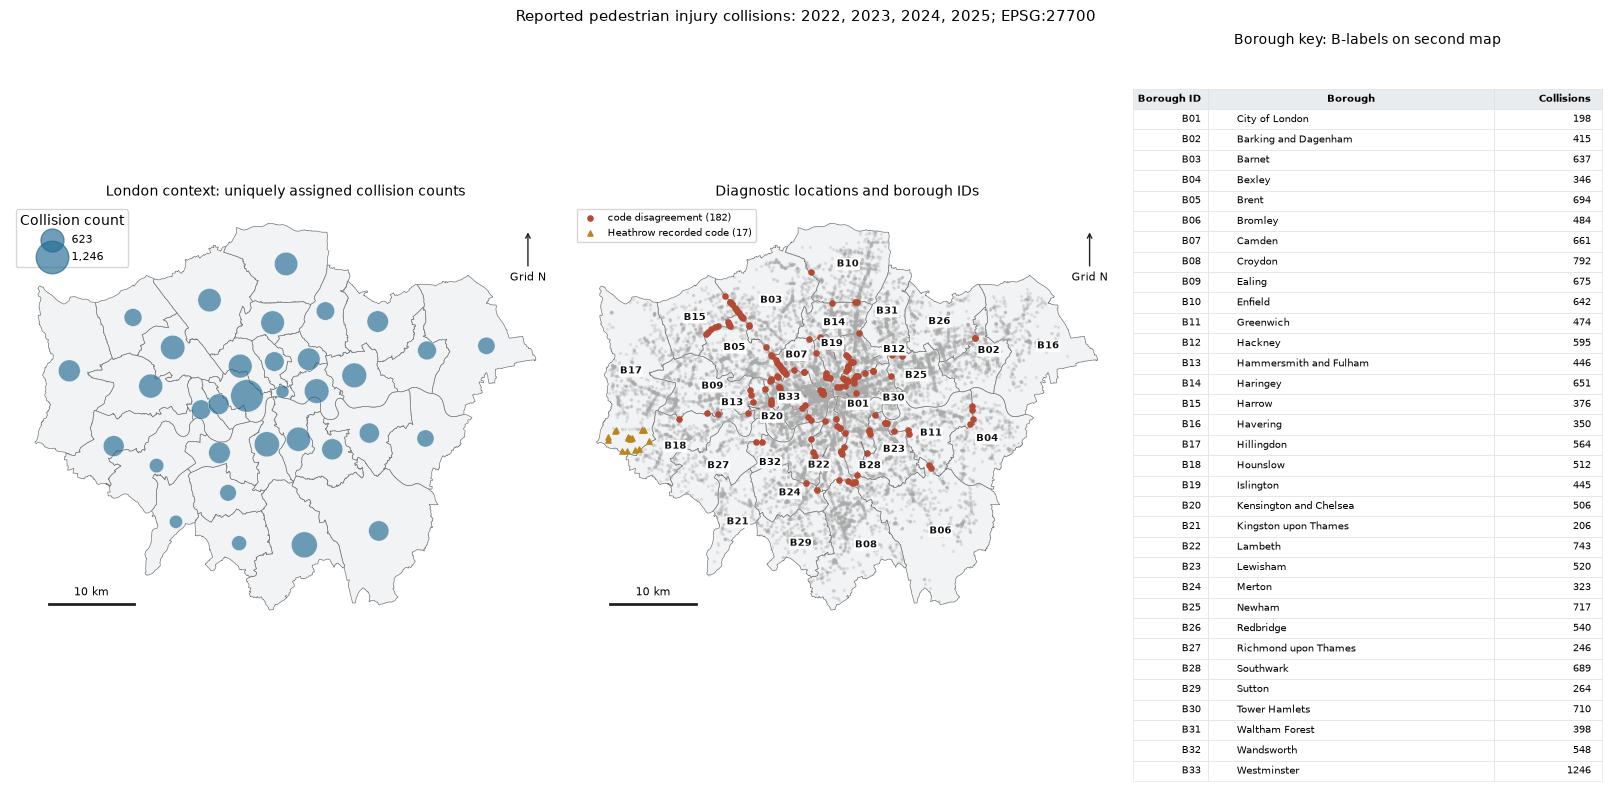

Sources: DfT collisions/casualties; ONS December 2024 BFE boundaries. See references R01/R05/R06.
Geometric totals exclude unresolved memberships; unusable-coordinate cases are retained in the audit.
Before report reuse, add the product-specific ONS/OS attribution and review the final map layout.


In [7]:
map_data = london.merge(borough_summary[[CODE, "geometric_total"]], on=CODE, how="left").sort_values(CODE).reset_index(drop=True)
map_data["map_id"] = [f"B{number:02d}" for number in range(1, len(map_data) + 1)]
borough_key = map_data[["map_id", NAME, "geometric_total"]].rename(
    columns={"map_id": "Borough ID", NAME: "Borough", "geometric_total": "Collisions"})
anchors = map_data.geometry.representative_point()
diagnostic_index = audit.index[grid_usable & (issue | audit["is_heathrow"])]
show_diagnostic = len(diagnostic_index) > 0
# Keep a separate borough locator even when there are no diagnostic cases.
map_panels = 2
fig, axes = plt.subplots(1, map_panels + 1,
                         figsize=(16, 7.8),
                         gridspec_kw={"width_ratios": [1] * map_panels + [0.85]},
                         layout="constrained", squeeze=False)
ax = axes[0, 0]
map_data.plot(ax=ax, facecolor="#f1f3f4", edgecolor="#777777", linewidth=0.5)
maximum = max(int(map_data["geometric_total"].max()), 1)
ax.scatter(anchors.x, anchors.y, s=map_data["geometric_total"] / maximum * 550,
           color="#246A94", alpha=0.65, edgecolors="white", linewidths=0.4)
legend_values = sorted(set([maximum, max(1, maximum // 2)]))
handles = [ax.scatter([], [], s=value / maximum * 550, color="#246A94", alpha=0.65,
                      label=f"{value:,}") for value in legend_values]
ax.legend(handles=handles, title="Collision count", loc="upper left", frameon=True, fontsize=8)
ax.set_title("London context: uniquely assigned collision counts", fontsize=10)
ax = axes[0, 1]
london.plot(ax=ax, facecolor="#f1f3f4", edgecolor="#777777", linewidth=0.5, zorder=0)
if show_diagnostic:
    background_index = audit.index[grid_usable & relevant]
    points.loc[background_index].plot(ax=ax, color="#aaaaaa", markersize=2, alpha=0.2, zorder=1)
    categories = pd.Series("code disagreement", index=diagnostic_index)
    unresolved_index = audit.index[grid_usable & relevant & ~unique]
    categories.loc[categories.index.intersection(unresolved_index)] = "unresolved membership"
    # The table retains both attributes when a Heathrow point is also a disagreement.
    heathrow_index = audit.index[grid_usable & audit["is_heathrow"]]
    categories.loc[categories.index.intersection(heathrow_index)] = "Heathrow recorded code"
    for label, colour, marker in [
        ("code disagreement", "#b44a34", "o"),
        ("unresolved membership", "#76518c", "x"),
        ("Heathrow recorded code", "#bb861b", "^")
    ]:
        indices = categories.index[categories.eq(label)]
        if len(indices):
            points.loc[indices].plot(ax=ax, color=colour, marker=marker, markersize=14,
                                     label=f"{label} ({len(indices):,})", zorder=5)
    ax.legend(loc="upper left", fontsize=7)
    ax.set_title("Diagnostic locations and borough IDs", fontsize=10)
else:
    ax.set_title("London borough locator", fontsize=10)
# Offset crowded central labels and keep white-backed IDs above diagnostic markers.
# This overview prioritises legibility; use the audit and section 3.8 for individual points.
label_offsets = {"E09000001": (10, -9), "E09000007": (-4, 8),
                 "E09000012": (17, 7), "E09000013": (-22, 5),
                 "E09000019": (-3, 13), "E09000020": (-6, -9),
                 "E09000022": (-7, -15), "E09000028": (7, -19),
                 "E09000030": (11, -5), "E09000032": (-8, -7),
                 "E09000033": (-14, -1)}
for row, anchor in zip(map_data.itertuples(index=False), anchors, strict=True):
    offset = label_offsets.get(getattr(row, CODE), (0, 0))
    ax.annotate(str(row.map_id), xy=(anchor.x, anchor.y), xytext=offset,
                textcoords="offset points", ha="center", va="center",
                fontsize=7, fontweight="bold", color="#111111", zorder=7,
                bbox={"boxstyle": "round,pad=0.12", "fc": "white", "ec": "none", "alpha": 1.0},
                arrowprops={"arrowstyle": "-", "color": "#555555", "lw": 0.5}
                if offset != (0, 0) else None)
key_ax = axes[0, -1]
key_ax.set_axis_off()
key_ax.set_title("Borough key: B-labels on second map", fontsize=10)
key_table = key_ax.table(cellText=borough_key.values.tolist(),
                         colLabels=borough_key.columns.tolist(), cellLoc="left",
                         colWidths=[0.16, 0.61, 0.23], bbox=[0, 0, 1, 0.95])
key_table.auto_set_font_size(False)
key_table.set_fontsize(7)
for (row, col), cell in key_table.get_celld().items():
    cell.set_edgecolor("#dddddd")
    cell.set_linewidth(0.4)
    if row == 0:
        cell.set_facecolor("#e8ecef")
        cell.set_text_props(weight="bold")
    if col in (0, 2):
        cell.get_text().set_ha("right")
for ax in axes[0, :map_panels]:
    ax.set_aspect("equal", adjustable="box")
    ax.set_axis_off()
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    x0, y0 = xmin + (xmax-xmin)*0.07, ymin + (ymax-ymin)*0.06
    ax.plot([x0, x0+10000], [y0, y0], color="#222222", linewidth=2)
    ax.text(x0+5000, y0+(ymax-ymin)*0.02, "10 km", ha="center", fontsize=8)
    ax.annotate("Grid N", xy=(0.94, 0.94), xytext=(0.94, 0.82),
                xycoords="axes fraction", ha="center", fontsize=8,
                arrowprops={"arrowstyle": "->", "color": "#222222"})
period_label = ", ".join(sorted(audit["source_file_year"].unique()))
fig.suptitle(f"Reported pedestrian injury collisions: {period_label}; EPSG:27700", fontsize=11)
plt.show()
print("Sources: DfT collisions/casualties; ONS December 2024 BFE boundaries. See references R01/R05/R06.")
print("Geometric totals exclude unresolved memberships; unusable-coordinate cases are retained in the audit.")
print("Before report reuse, add the product-specific ONS/OS attribution and review the final map layout.")

**Findings:** the saved figure shows borough totals on the first map and B-prefixed borough identifiers with 182 district differences and 17 Heathrow-coded events on the second map. The previously obscured central identifiers are readable in the inspected saved figure and correspond to the name/count key. Label boxes can conceal individual points; detailed audits, final attribution and report-layout checks remain necessary.


### 3.8 Selected collision inspection in Python

**Purpose:** reproduce the two browser-inspected examples using fixed 50 m-wide views, labelled borough boundaries and point centres in EPSG:27700. Compare the recorded and geometric codes without changing membership or reading screenshot files. These examples check rendering and attribute consistency, not positional accuracy or all 182 differences.

**Export:** the input cell enables a 300 dpi PNG export that retains identical PNGs and replaces changed PNGs after a complete save to `../evidence/membership_boundary_examples.png`; set `EXPORT_FIGURES = False` for inline-only use. The saved output reports an unchanged PNG retained by the revised helper; the exported example figure has been visually inspected.


Figure unchanged; kept existing PNG: ../evidence/membership_boundary_examples.png


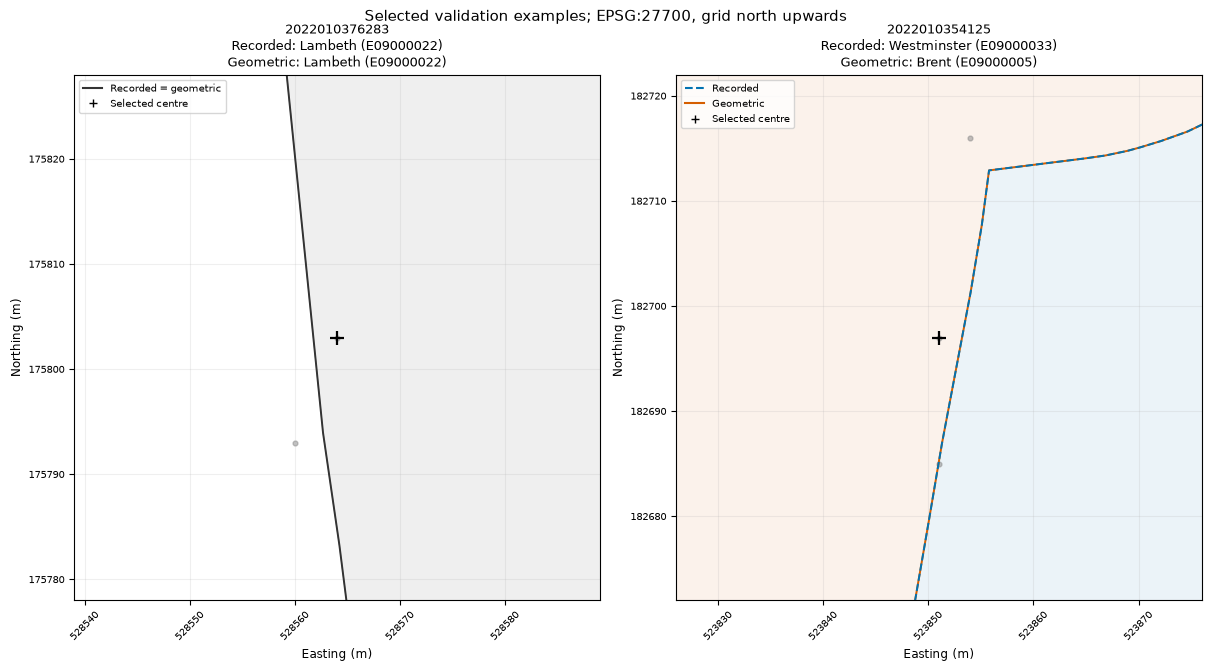

,collision_index,source_file_year,recorded_code,geometric_code,membership_status,distance_to_recorded_polygon_m
0,2022010376283,2022,E09000022,E09000022,unique_interior,0.000000
1,2022010354125,2022,E09000033,E09000005,unique_interior,2.162239


Sources: DfT collision/casualty data and ONS December 2024 BFE boundaries; references R01/R05/R06.
Point centres determine membership; symbol size can overlap a boundary. No basemap accuracy check is performed.
For report reuse, add the product-specific ONS/OS attribution and review the final layout.


In [8]:
from matplotlib.lines import Line2D

# These examples were inspected in Mapshaper; they do not select the study borough.
INSPECTION_IDS = ("2022010376283", "2022010354125")
INSPECTION_HALF_WIDTH_M = 25.0
if (not np.isfinite(INSPECTION_HALF_WIDTH_M) or INSPECTION_HALF_WIDTH_M <= 0
        or len(INSPECTION_IDS) != 2 or len(set(INSPECTION_IDS)) != 2):
    raise ValueError("Choose two distinct collision IDs and a finite positive inspection half-width.")
if points.crs != london.crs or london.crs != CRS.from_user_input(GRID_CRS):
    raise ValueError("Inspection points and boundaries must use the documented analysis CRS.")
inspection_audit = audit.set_index("collision_index")
inspection_geometry = points.set_index("collision_index").geometry
missing_ids = sorted(set(INSPECTION_IDS) - set(inspection_geometry.index))
if missing_ids:
    raise ValueError(f"Inspection IDs lack usable points: {missing_ids}. Check the input version.")
inspection_cases = inspection_audit.loc[list(INSPECTION_IDS)].copy()
if not inspection_cases["membership_status"].eq("unique_interior").all():
    raise ValueError("These inspection examples require uniquely resolved London membership.")
inspection_names = london.set_index(CODE)[NAME]
context_points = points.loc[points.index.intersection(audit.index[grid_usable & relevant])]
inspection_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), layout="constrained")
for ax, collision_id in zip(axes, INSPECTION_IDS, strict=True):
    case = inspection_cases.loc[collision_id]
    point = inspection_geometry.loc[collision_id]
    recorded, geometric = case["local_authority_ons_district"], case["geometric_london_code"]
    if recorded not in inspection_names.index or geometric not in inspection_names.index:
        raise ValueError(f"Inspection case {collision_id} does not have two recognised London codes.")
    xmin, xmax = point.x - INSPECTION_HALF_WIDTH_M, point.x + INSPECTION_HALF_WIDTH_M
    ymin, ymax = point.y - INSPECTION_HALF_WIDTH_M, point.y + INSPECTION_HALF_WIDTH_M
    window_boundaries = london.cx[xmin:xmax, ymin:ymax]
    if not window_boundaries.empty:
        window_boundaries.boundary.plot(ax=ax, color="#bbbbbb", linewidth=0.7)
    handles = []
    styles = ([(recorded, "Recorded = geometric", "#333333", "-")] if recorded == geometric else [
        (recorded, "Recorded", "#0072B2", "--"),
        (geometric, "Geometric", "#D55E00", "-")])
    for district, label, colour, line_style in styles:
        district_layer = london.loc[london[CODE].eq(district)]
        district_layer.plot(ax=ax, facecolor=colour, edgecolor="none", alpha=0.08, zorder=0)
        district_layer.boundary.plot(
            ax=ax, color=colour, linestyle=line_style, linewidth=1.4,
            zorder=3 if label == "Recorded" else 2)
        handles.append(Line2D([], [], color=colour, linestyle=line_style, label=label))
    nearby = context_points.cx[xmin:xmax, ymin:ymax]
    if not nearby.empty:
        ax.scatter(nearby.geometry.x, nearby.geometry.y, s=12, color="#888888", alpha=0.5)
    ax.scatter([point.x], [point.y], marker="+", s=90, linewidths=1.6,
               color="#000000", zorder=5)
    handles.append(Line2D([], [], color="#000000", marker="+", linestyle="None", label="Selected centre"))
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal",
           xlabel="Easting (m)", ylabel="Northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(alpha=0.2)
    ax.set_title(f"{collision_id}\nRecorded: {inspection_names[recorded]} ({recorded})\n"
                 f"Geometric: {inspection_names[geometric]} ({geometric})", fontsize=9)
    ax.legend(handles=handles, loc="upper left", fontsize=7)
    distance = float(point.distance(london.loc[london[CODE].eq(recorded)].geometry.iloc[0]))
    inspection_rows.append({"collision_index": collision_id, "source_file_year": case["source_file_year"],
        "recorded_code": recorded, "geometric_code": geometric,
        "membership_status": case["membership_status"],
        "distance_to_recorded_polygon_m": distance})
fig.suptitle("Selected validation examples; EPSG:27700, grid north upwards", fontsize=11)
save_report_figure(fig, "membership_boundary_examples.png")
plt.show()
display(pd.DataFrame(inspection_rows))
print("Sources: DfT collision/casualty data and ONS December 2024 BFE boundaries; references R01/R05/R06.")
print("Point centres determine membership; symbol size can overlap a boundary. No basemap accuracy check is performed.")
print("For report reuse, add the product-specific ONS/OS attribution and review the final layout.")


**Findings:** the saved maps and table show matching Lambeth codes for `2022010376283` and recorded Westminster/geometric Brent codes for `2022010354125`, consistent with the earlier Mapshaper inspection. Distances to the recorded polygons are 0 m and approximately 2.16 m respectively; 0 m means inside the polygon, not zero distance to its boundary. These two examples check rendering and attribute consistency, not independent positional accuracy or all disagreements: [R17](../docs/references.md#r17).


### 3.9 Audit summary and scope of validation

**Purpose:** summarise evaluated checks separately from unperformed coordinate agreement and later study decisions. Notebook 02 does not select a borough or infer concentrations; notebooks 03–04 apply the adopted fixed-footprint study frame, which does not require a claim of historically identical polygons: [R15–R16](../docs/references.md#r15).


In [9]:
metrics = {
    "national_candidates": len(audit),
    "recorded_london_differences_evaluated": len(district_diagnostics),
    "usable_grid_pairs": int(grid_usable.sum()),
    "unusable_grid_pairs": int((~grid_usable).sum()),
    "unique_london_interior": int(unique.sum()),
    "boundary_touch": int(audit["membership_status"].eq("boundary_touch").sum()),
    "multiple_or_inconsistent": int(audit["membership_status"].eq("multiple_or_inconsistent").sum()),
    "recorded_london_unresolved": int((audit["is_recorded_london"] & ~unique).sum()),
    "unique_membership_code_disagreements": int(audit["flag_recorded_code_disagrees"].sum()),
    "heathrow_recorded_events": int(audit["is_heathrow"].sum()),
    "coordinate_agreement_checked_rows": int(audit["flag_grid_lonlat_disagree"].notna().sum()),
    "positive_area_boundary_pairs": len(boundary_overlaps),
}
validation_summary = pd.Series(metrics, name="count")
display(validation_summary)
audit["spatial_validation_status"] = "london_membership_evaluated_final_scope_pending"
audit.loc[~grid_usable, "spatial_validation_status"] = "unusable_grid_membership_not_checked"
run_metadata = {"executed_utc": datetime.now(timezone.utc).isoformat(), "versions": versions,
    "input_sha256": input_hashes, "boundary_vintage": "December 2024",
    "source_boundary_crs": source_boundary_crs, "analysis_crs": GRID_CRS,
    "coordinate_method": coordinate_method, "metrics": metrics,
    "district_difference_method": {"distance": "point to recorded district polygon, metres",
        "pair_relation": "exact topology; shared edge, point only, disjoint or inconsistent",
        "threshold_m": None, "highway_comparison": "location-derived consistency evidence",
        "collision_sources": [path.name for path in collision_input_paths]},
    "temporal_suitability": "not_checked", "selected_borough": None, "final_period": None,
    "boundary_rule": "Assign only exactly one within and one intersects match; retain all other cases for review."}
print("No borough selected and no final spatial exclusions applied. Coordinate agreement status:", coordinate_method["status"])

national_candidates                      74682
recorded_london_differences_evaluated      182
usable_grid_pairs                        74675
unusable_grid_pairs                          7
unique_london_interior                   17613
boundary_touch                               0
multiple_or_inconsistent                     0
recorded_london_unresolved                   0
unique_membership_code_disagreements       199
heathrow_recorded_events                    17
coordinate_agreement_checked_rows            0
positive_area_boundary_pairs                 0
Name: count, dtype: int64

No borough selected and no final spatial exclusions applied. Coordinate agreement status: not_checked


**Findings:** the saved audit summary reports 182 evaluated London district differences, 199 total code differences and no unresolved recorded-London memberships or positive-area overlaps. Coordinate agreement, temporal suitability and final study scope remain unresolved.


### 3.10 Validation exports for inspection

**Purpose:** export the audit, London layers, summaries and provenance to `OUTPUT_DIR`, retaining unusable points in the CSV audit. If any named output exists, skip all writes and report completeness and input-hash agreement; matching hashes do not verify code or artifact contents.


In [10]:
outputs = {name: OUTPUT_DIR / name for name in [
    "london_validation.gpkg", "collision_validation_audit.csv", "borough_selection_evidence.csv",
    "recorded_geometric_comparison.csv", "boundary_overlaps.csv", "validation_run.json",
    "district_difference_diagnostics.csv", "district_differences_by_year.csv", "district_differences_by_pair.csv"
]}
input_paths = {p.resolve() for p in [BOUNDARY_PATH, CANDIDATE_PATH, GUIDE_PATH, manifest_path, *collision_input_paths]}
if any(path.resolve() in input_paths for path in outputs.values()):
    raise ValueError("Output path conflicts with an input.")
existing_outputs = [name for name, path in outputs.items() if path.exists()]
if existing_outputs:
    print("Export skipped: output files already exist in", OUTPUT_DIR)
    print("Existing files:", existing_outputs)
    missing_outputs = [name for name in outputs if name not in existing_outputs]
    if missing_outputs:
        print("Output set is incomplete; missing files:", missing_outputs)
    try:
        stored_metadata = json.loads(outputs["validation_run.json"].read_text(encoding="utf-8"))
        if not isinstance(stored_metadata, dict):
            raise ValueError("Stored metadata is not an object.")
        stored_hashes = stored_metadata.get("input_sha256")
        if not isinstance(stored_hashes, dict) or set(stored_hashes) != set(input_hashes):
            print("Input provenance: unverifiable (stored input hashes are incomplete).")
        elif stored_hashes == input_hashes:
            print("Input provenance: match. This does not verify code, settings or exported artifact contents.")
        else:
            print("Input provenance: mismatch. Existing exports belong to different inputs.")
    except (OSError, ValueError):
        print("Input provenance: unverifiable (stored run metadata is missing or unreadable).")
    print("Existing files were retained; they were not regenerated from this execution.")
    print("To save current results separately, choose a new OUTPUT_DIR in the parameter cell.")
else:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    export_columns = ["collision_index", "source_file_year", "local_authority_ons_district",
        "geometric_london_code", "membership_status", "interior_matches", "intersecting_matches",
        "flag_recorded_code_disagrees", "is_heathrow", "coordinate_offset_m", "flag_grid_lonlat_disagree"]
    export_index = audit.index[grid_usable & relevant]
    export_points = gpd.GeoDataFrame(audit.loc[export_index, export_columns].copy(),
                                   geometry=points.geometry.reindex(export_index), crs=GRID_CRS)
    london.to_file(outputs["london_validation.gpkg"], layer="london_boundaries", driver="GPKG", engine="pyogrio")
    if not export_points.empty:
        export_points.to_file(outputs["london_validation.gpkg"], layer="collision_validation", driver="GPKG", engine="pyogrio", mode="a")
    audit.to_csv(outputs["collision_validation_audit.csv"], index=False)
    borough_summary.to_csv(outputs["borough_selection_evidence.csv"], index=False)
    comparison.to_csv(outputs["recorded_geometric_comparison.csv"])
    boundary_overlaps.to_csv(outputs["boundary_overlaps.csv"], index=False)
    district_diagnostics.to_csv(outputs["district_difference_diagnostics.csv"], index=False)
    difference_by_year.to_csv(outputs["district_differences_by_year.csv"], index=False)
    difference_by_pair.to_csv(outputs["district_differences_by_pair.csv"], index=False)
    outputs["validation_run.json"].write_text(json.dumps(run_metadata, indent=2)+"\n", encoding="utf-8")
    print("Exported validation evidence:", [path.name for path in outputs.values()])
    print("GeoPackage layers: london_boundaries and, when nonempty, collision_validation. CRS: EPSG:27700.")


Export skipped: output files already exist in ../data/derived/spatial_validation_closure
Existing files: ['london_validation.gpkg', 'collision_validation_audit.csv', 'borough_selection_evidence.csv', 'recorded_geometric_comparison.csv', 'boundary_overlaps.csv', 'validation_run.json', 'district_difference_diagnostics.csv', 'district_differences_by_year.csv', 'district_differences_by_pair.csv']
Input provenance: match. This does not verify code, settings or exported artifact contents.
Existing files were retained; they were not regenerated from this execution.
To save current results separately, choose a new OUTPUT_DIR in the parameter cell.


**Findings:** the saved export message lists all nine retained validation files and matching input hashes, without regenerating them. Both inspection figures are saved, and `membership_boundary_examples.png` was retained unchanged by the new PNG helper. Final PDF-size review and product-specific attribution remain pending.
